# 02. Train / validation / test split

In [1]:
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path.cwd().parent
DATA_DIR = PROJECT_DIR / "data" / "processed" / "grid"

labels = pd.read_csv(DATA_DIR / "labels.csv")

print("Rows:", len(labels))
print(labels.head())

Rows: 3960
  speaker    name                   sentence
0      s1  bbaf2n      bin blue at f two now
1      s1  bbaf3s   bin blue at f three soon
2      s1  bbaf4p  bin blue at f four please
3      s1  bbaf5a   bin blue at f five again
4      s1  bbal6n      bin blue at l six now


In [2]:
TEST_SPEAKER = "s4"
VAL_FRACTION = 0.1

labels["split"] = "train"

is_test = labels["speaker"] == TEST_SPEAKER
labels.loc[is_test, "split"] = "test"

train_rows = labels[labels["split"] == "train"]
val_rows = train_rows.sample(frac=VAL_FRACTION, random_state=42)
labels.loc[val_rows.index, "split"] = "val"

In [3]:
print(labels["split"].value_counts())
print()
print(labels.groupby("split")["speaker"].unique())

labels.to_csv(DATA_DIR / "labels_split.csv", index=False)

split
train    2670
test      993
val       297
Name: count, dtype: int64

split
test             [s4]
train    [s1, s2, s3]
val      [s1, s2, s3]
Name: speaker, dtype: object


# 03. Baseline: word classification

In [4]:
from pathlib import Path
import numpy as np
import pandas as pd

PROJECT_DIR = Path.cwd().parent
DATA_DIR = PROJECT_DIR / "data" / "processed" / "grid"
ALIGN_DIR = PROJECT_DIR / "data" / "raw" / "grid" / "alignments"

labels = pd.read_csv(DATA_DIR / "labels_split.csv")

print("Rows:", len(labels))
print(labels["split"].value_counts())

Rows: 3960
split
train    2670
test      993
val       297
Name: count, dtype: int64


In [5]:
SKIP_WORDS = ["sil", "sp"]


def read_words_with_frames(path):
    text = path.read_text()
    lines = text.splitlines()

    words = []
    for line in lines:
        parts = line.split()
        start = int(parts[0])
        end = int(parts[1])
        word = parts[2]

        if word in SKIP_WORDS:
            continue

        start_frame = start // 1000
        end_frame = end // 1000

        words.append((word, start_frame, end_frame))

    return words


test_path = ALIGN_DIR / "s1" / "bbaf2n.align"
for item in read_words_with_frames(test_path):
    print(item)

('bin', 23, 29)
('blue', 29, 34)
('at', 34, 35)
('f', 35, 41)
('two', 41, 47)
('now', 47, 53)


# Word features

In [6]:
import cv2

NUM_FRAMES = 5
SMALL_WIDTH = 20
SMALL_HEIGHT = 10


def word_features(video_array, start_frame, end_frame):
    if end_frame <= start_frame:
        end_frame = start_frame + 1

    clip = video_array[start_frame:end_frame]

    positions = np.linspace(0, len(clip) - 1, NUM_FRAMES)

    small_frames = []
    for position in positions:
        frame_index = int(round(position))
        frame = clip[frame_index]
        small = cv2.resize(frame, (SMALL_WIDTH, SMALL_HEIGHT))
        small_frames.append(small)

    features = np.array(small_frames).flatten() / 255.0
    return features

In [7]:
video_array = np.load(DATA_DIR / "s1" / "bbaf2n.npy")
words = read_words_with_frames(test_path)

for word, start_frame, end_frame in words:
    features = word_features(video_array, start_frame, end_frame)
    print(word, features.shape)

bin (1000,)
blue (1000,)
at (1000,)
f (1000,)
two (1000,)
now (1000,)


## 4. Build datasets

In [8]:
def build_dataset(split_name):
    rows = labels[labels["split"] == split_name]

    X = []
    y = []

    for _, row in rows.iterrows():
        speaker = row["speaker"]
        name = row["name"]

        video_array = np.load(DATA_DIR / speaker / (name + ".npy"))
        align_path = ALIGN_DIR / speaker / (name + ".align")

        for word, start_frame, end_frame in read_words_with_frames(align_path):
            features = word_features(video_array, start_frame, end_frame)
            X.append(features)
            y.append(word)

    return np.array(X), np.array(y)


X_train, y_train = build_dataset("train")
X_val, y_val = build_dataset("val")
X_test, y_test = build_dataset("test")

print("Train:", X_train.shape)
print("Val:", X_val.shape)
print("Test:", X_test.shape)

Train: (16020, 1000)
Val: (1782, 1000)
Test: (5958, 1000)


knn

In [10]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

val_accuracy = accuracy_score(y_val, knn.predict(X_val))
print("kNN (k=5) val accuracy:", round(val_accuracy, 3))

kNN (k=5) val accuracy: 0.713


In [11]:
val_predictions = knn.predict(X_val)

comparison = pd.DataFrame({
    "true": y_val,
    "predicted": val_predictions,
})
comparison["correct"] = comparison["true"] == comparison["predicted"]

print(comparison.head(12))
print()
print("Correct:", comparison["correct"].sum(), "of", len(comparison))

     true predicted  correct
0     bin       bin     True
1    blue      blue     True
2      at        at     True
3       f       now    False
4     two      soon    False
5     now       now     True
6     bin       bin     True
7    blue      blue     True
8      in        in     True
9       e        at    False
10  eight     eight     True
11    now       now     True

Correct: 1271 of 1782


### 6. Tune kNN

In [13]:
k_values = [1, 3, 5, 7, 9, 15, 25]
weight_options = ["uniform", "distance"]

tuning_rows = []

for weights in weight_options:
    for k in k_values:
        model = KNeighborsClassifier(n_neighbors=k, weights=weights)
        model.fit(X_train, y_train)

        accuracy = accuracy_score(y_val, model.predict(X_val))

        row = {"k": k, "weights": weights, "val_accuracy": round(accuracy, 3)}
        tuning_rows.append(row)

        print(weights, "k =", k, "->", round(accuracy, 3))

tuning = pd.DataFrame(tuning_rows)

best_row = tuning.loc[tuning["val_accuracy"].idxmax()]
best_k = int(best_row["k"])
best_weights = best_row["weights"]

print()
print("Best:", best_weights, "k =", best_k, "->", best_row["val_accuracy"])

uniform k = 1 -> 0.709
uniform k = 3 -> 0.708
uniform k = 5 -> 0.713
uniform k = 7 -> 0.72
uniform k = 9 -> 0.716
uniform k = 15 -> 0.713
uniform k = 25 -> 0.696
distance k = 1 -> 0.709
distance k = 3 -> 0.724
distance k = 5 -> 0.735
distance k = 7 -> 0.736
distance k = 9 -> 0.737
distance k = 15 -> 0.728
distance k = 25 -> 0.71

Best: distance k = 9 -> 0.737


In [14]:
import joblib

final_knn = KNeighborsClassifier(n_neighbors=best_k, weights=best_weights)
final_knn.fit(X_train, y_train)

final_val_accuracy = accuracy_score(y_val, final_knn.predict(X_val))
final_test_accuracy = accuracy_score(y_test, final_knn.predict(X_test))

print("Final kNN:", best_weights, "k =", best_k)
print("Val accuracy:", round(final_val_accuracy, 3))
print("Test accuracy:", round(final_test_accuracy, 3))

MODELS_DIR = PROJECT_DIR / "models"
MODELS_DIR.mkdir(exist_ok=True)
joblib.dump(final_knn, MODELS_DIR / "knn_baseline.joblib")

results = pd.DataFrame([{
    "model": "knn",
    "k": best_k,
    "weights": best_weights,
    "val_accuracy": round(final_val_accuracy, 3),
    "test_accuracy": round(final_test_accuracy, 3),
}])
results.to_csv(DATA_DIR / "baseline_results.csv", index=False)
print(results)

Final kNN: distance k = 9
Val accuracy: 0.737
Test accuracy: 0.122
  model  k   weights  val_accuracy  test_accuracy
0   knn  9  distance         0.737          0.122


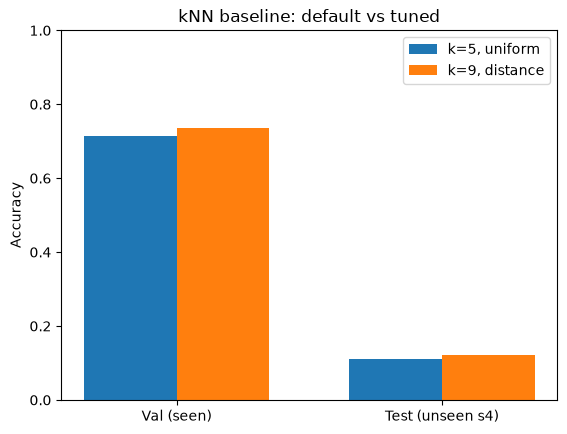

In [15]:
import matplotlib.pyplot as plt

labels_x = ["Val (seen)", "Test (unseen s4)"]
default_scores = [0.713, 0.110]
tuned_scores = [final_val_accuracy, final_test_accuracy]

positions = np.arange(len(labels_x))
bar_width = 0.35

plt.bar(positions - bar_width / 2, default_scores, bar_width, label="k=5, uniform")
plt.bar(positions + bar_width / 2, tuned_scores, bar_width, label="k=9, distance")

plt.xticks(positions, labels_x)
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.title("kNN baseline: default vs tuned")
plt.legend()

plt.savefig(PROJECT_DIR / "images" / "knn_baseline.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Feature experiments


In [16]:
def mean_face_features(video_array, start_frame, end_frame):
    mean_frame = video_array.mean(axis=0)
    centered = video_array - mean_frame
    return word_features(centered, start_frame, end_frame)


def motion_features(video_array, start_frame, end_frame):
    features = word_features(video_array, start_frame, end_frame)
    frames = features.reshape(NUM_FRAMES, SMALL_HEIGHT, SMALL_WIDTH)
    differences = np.diff(frames, axis=0)
    return differences.flatten()

In [17]:
def build_dataset(split_name, feature_function):
    rows = labels[labels["split"] == split_name]

    X = []
    y = []

    for _, row in rows.iterrows():
        speaker = row["speaker"]
        name = row["name"]

        video_array = np.load(DATA_DIR / speaker / (name + ".npy"))
        align_path = ALIGN_DIR / speaker / (name + ".align")

        for word, start_frame, end_frame in read_words_with_frames(align_path):
            features = feature_function(video_array, start_frame, end_frame)
            X.append(features)
            y.append(word)

    return np.array(X), np.array(y)

In [18]:
experiments = {
    "pixels": word_features,
    "mean_face": mean_face_features,
    "motion": motion_features,
}

experiment_rows = []

for name, feature_function in experiments.items():
    X_train_exp, y_train_exp = build_dataset("train", feature_function)
    X_val_exp, y_val_exp = build_dataset("val", feature_function)
    X_test_exp, y_test_exp = build_dataset("test", feature_function)

    model = KNeighborsClassifier(n_neighbors=best_k, weights=best_weights)
    model.fit(X_train_exp, y_train_exp)

    val_acc = accuracy_score(y_val_exp, model.predict(X_val_exp))
    test_acc = accuracy_score(y_test_exp, model.predict(X_test_exp))

    experiment_rows.append({
        "features": name,
        "val_accuracy": round(val_acc, 3),
        "test_accuracy": round(test_acc, 3),
    })
    print(name, "done")

experiment_results = pd.DataFrame(experiment_rows)
experiment_results.to_csv(DATA_DIR / "feature_experiments.csv", index=False)
print(experiment_results)

pixels done
mean_face done
motion done
    features  val_accuracy  test_accuracy
0     pixels         0.737          0.122
1  mean_face         0.782          0.177
2     motion         0.631          0.049
